# P5 프로젝트 · 서울 따릉이 대여소의 이용 패턴 발견

**K-means 군집화 | 3주 Lab**

> **핵심 질문:** 서울 따릉이 대여소는 이용 시간에 따라 어떤 유형으로 나뉠까? **한 대여소에서 평일과 주말의 이용 패턴은 얼마나 다를까?**

P1에서는 자전거 이용량을 *예측*했습니다. P5에서는 정답이 없는 대여소 이용정보를 군집화하고, 발견한 유형이 의미 있는지 판단합니다.

| 주차 | 주요 활동 |
|---|---|
| **1주차** | 데이터의 의미, 이용량과 시간대별 패턴 살펴보기 |
| **2주차** | K-means로 대여소 유형 발견하기 |
| **3주차** | 평일·주말 패턴의 유사성 분석, 군집 해석, 운영 방안 제안 |

코드를 처음부터 만들기보다는 **실행 → 관찰 → 설정 변경 → 해석**에 집중하세요. **모의 데이터 결과를 실제 서울 따릉이의 분석 결과로 해석하면 안 됩니다.**

## 1주차 · 데이터를 이해하자

### 1. 데이터 불러오기

**한 행은 대여소 한 곳**, 모든 값은 **2025년** 이용정보를 뜻합니다.

| 변수 | 의미 |
|---|---|
| `annual_rentals`, `annual_returns` | 연간 대여·반납 총건수 |
| `m01`~`m12` | 각 월의 대여 총건수 |
| `r_wd_h08` | **2025년 평일** 오전 8시대의 대여 총건수 |
| `b_we_h18` | **2025년 주말** 오후 6시대의 반납 총건수 |

`r`은 대여, `b`는 반납, `wd`는 평일(월~금), `we`는 주말(토~일), `h08`은 08:00~08:59입니다. **시간대별 수치는 하루 평균이 아니라 1년간의 합계**입니다.

처음에는 동봉한 **모의 데이터**로 실행합니다. 실제 데이터를 준비한 경우 파일명만 바꿉니다.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_FILE = "p5_demo_station_profiles_2025.csv"  # 실제 데이터: p5_station_profiles_2025.csv
bike = pd.read_csv(DATA_FILE, dtype={"station_id": str})
bike.head()

,station_id,station_name,annual_rentals,annual_returns,m01,m02,m03,m04,m05,m06,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,1000,모의 대여소 001,31019,30287,1030,309,2088,4776,4021,4459,...,651,531,542,474,228,186,95,84,65,59
1,1001,모의 대여소 002,64659,69822,2809,3503,4963,3183,12916,9600,...,1218,1728,1689,1557,1249,889,732,495,263,278
2,1002,모의 대여소 003,19521,20877,466,2182,982,2301,2184,1534,...,870,1235,1536,1845,1687,1314,912,608,381,222
3,1003,모의 대여소 004,17339,17682,1041,502,1781,2085,1369,2126,...,323,319,305,329,287,259,195,146,102,76
4,1004,모의 대여소 005,50069,49158,1316,2806,3310,4401,3346,7388,...,1110,975,1000,712,578,373,243,130,103,92


### 2. 전체 이용 규모 살펴보기

먼저 연간 이용량을 확인합니다. **전체 대여·반납 합계**만 볼 것이 아니라, **대여소마다 이용량이 얼마나 다른지** 살펴보세요.

여기서 전체는 서울의 모든 대여소가 아니라 **현재 CSV에 포함된 분석 대상 대여소 전체**입니다. 대여와 반납을 더하면 하나의 이동을 두 번 셀 수 있으므로, 연간 이용 횟수처럼 해석하지 않습니다.

In [8]:
print(f"분석 대여소: {len(bike):,}곳")
print(f"연간 대여: {bike['annual_rentals'].sum():,}건")
print(f"연간 반납: {bike['annual_returns'].sum():,}건")

bike[["annual_rentals", "annual_returns"]].describe().round(0)

분석 대여소: 260곳
연간 대여: 9,454,923건
연간 반납: 9,472,380건


,annual_rentals,annual_returns
count,260.0,260.0
mean,36365.0,36432.0
std,18194.0,18393.0
min,3737.0,3544.0
25%,19749.0,19997.0
50%,35312.0,36126.0
75%,51233.0,52244.0
max,64899.0,70428.0


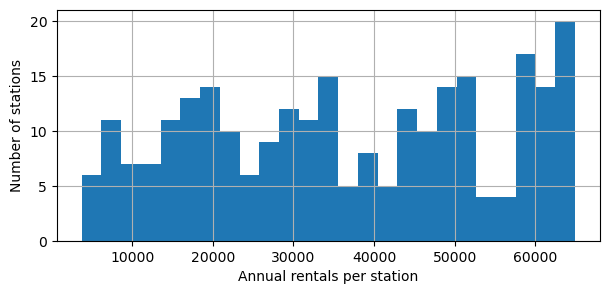

In [9]:
bike["annual_rentals"].hist(bins=25, figsize=(7, 3))
plt.xlabel("Annual rentals per station")
plt.ylabel("Number of stations")
plt.show()

**✍️ 생각해 보기**

- 평균과 중앙값은 얼마나 다른가요? 대여소별 이용량이 일부 대여소에 집중되어 있나요?
- 이용량이 큰 대여소와 작은 대여소를 구분하는 것만으로 이용 *패턴*까지 알 수 있을까요?

### 3. 평일·주말의 시간대별 이용량

2025년은 **평일 261일, 주말 104일**입니다. 공휴일도 월~금이면 평일로 계산합니다.

연간 합계를 그대로 비교하면 날짜 수가 많은 평일의 이용량이 크게 보일 수 있습니다. 따라서 **평일과 주말의 해당 시간대 연간 건수를 각각 날짜 수로 나누어** 하루 평균을 비교합니다.

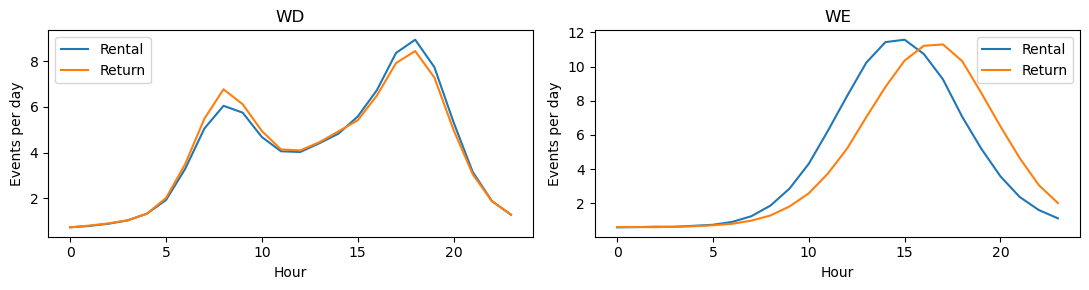

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ["wd", "we"], [261, 104]):
    for kind, label in [("r", "Rental"), ("b", "Return")]:
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), bike[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

**✍️ 기록 ①**

- 평일과 주말에서 대여·반납이 집중되는 시간은 언제인가요?
- 대여와 반납이 같은 시간대에 서로 다르다면 어떤 이유가 있을까요? **그래프에서 확인한 사실**과 **추측**을 구분하세요.

## 2주차 · K-means로 대여소의 이용 유형을 발견하자

### 4. 이용건수가 아니라 시간대별 비중으로 비교하기

이용량이 10배 다른 두 대여소라도 **하루 중 자전거를 빌리는 시간 분포**는 비슷할 수 있습니다. 따라서 이용량의 크기보다 **언제 빌리고 언제 반납하는지**에 주목합니다.

평일과 주말을 공정하게 비교하기 위해 다음 두 단계를 사용합니다.

1. **날짜 수 보정:** 평일 시간대별 총건수는 261일, 주말은 104일로 나누어 하루 평균을 구합니다.
2. **비중 계산:** 대여 48개 시간대의 하루 평균값을 그 합으로 나눕니다. 반납 48개도 같은 방법으로 계산합니다.

예를 들어 평일 하루 평균과 주말 하루 평균 대여량이 같으면, 두 요일 구분의 비중 합도 각각 50%가 됩니다. 주말 하루 평균 이용량이 두 배라면 주말이 더 큰 비중을 갖습니다.

대여 48개 비중의 합은 **1**, 반납 48개 비중의 합도 **1**입니다. 합쳐서 **96개 특성**을 K-means에 사용합니다. 여기서 비중은 *연간 총건수에 대한 비중*이 아니라, **평일·주말 하루 평균을 합친 값에 대한 비중**입니다.

In [11]:
rent_cols = [f"r_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]
return_cols = [f"b_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]

# 평일과 주말의 날짜 수 차이 보정
daily = bike[rent_cols + return_cols].astype(float).copy()
daily[rent_cols[:24] + return_cols[:24]] /= 261
daily[rent_cols[24:] + return_cols[24:]] /= 104

rent_share = daily[rent_cols].div(daily[rent_cols].sum(axis=1), axis=0)
return_share = daily[return_cols].div(daily[return_cols].sum(axis=1), axis=0)
X = pd.concat([rent_share, return_share], axis=1)
X.head()

,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05,r_wd_h06,r_wd_h07,r_wd_h08,r_wd_h09,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,0.003681,0.002564,0.002945,0.003377,0.006170,0.017468,0.044203,0.074137,0.093280,0.092315,...,0.042262,0.034472,0.035186,0.030771,0.014801,0.012075,0.006167,0.005453,0.004220,0.003830
1,0.002689,0.003199,0.003684,0.003080,0.004395,0.007274,0.009964,0.015330,0.017534,0.017783,...,0.033614,0.047688,0.046612,0.042969,0.034469,0.024534,0.020201,0.013661,0.007258,0.007672
2,0.002482,0.002482,0.002454,0.002318,0.002372,0.002618,0.003027,0.002836,0.003872,0.004418,...,0.055729,0.079110,0.098391,0.118185,0.108064,0.084170,0.058420,0.038946,0.024406,0.014221
3,0.007268,0.007870,0.007698,0.009074,0.012213,0.016557,0.019051,0.020728,0.025845,0.024383,...,0.034300,0.033875,0.032388,0.034937,0.030477,0.027504,0.020707,0.015504,0.010832,0.008071
4,0.003505,0.002993,0.003691,0.004001,0.006854,0.017338,0.041049,0.075910,0.080748,0.074995,...,0.043713,0.038397,0.039381,0.028040,0.022762,0.014689,0.009570,0.005120,0.004056,0.003623


### 5. 군집 수는 몇 개가 적절할까?

K-means는 대여소들의 **평일 대여·반납 + 주말 대여·반납 패턴을 종합해** 비슷한 대여소끼리 묶습니다.

군집 수 `k`를 2~6으로 바꾸며 **실루엣 점수**를 비교해 보세요. 점수가 높을수록 군집이 상대적으로 잘 구분되지만, **점수가 높다고 군집에 반드시 의미 있는 이름을 붙일 수 있는 것은 아닙니다.**

In [12]:
results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels, sample_size=500, random_state=42)
    results.append([k, score])

scores = pd.DataFrame(results, columns=["k", "silhouette"])
scores

c:\Users\gslee\miniforge3\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than 

,k,silhouette
0,2,0.586581
1,3,0.686672
2,4,0.803670
3,5,0.612738
4,6,0.436279


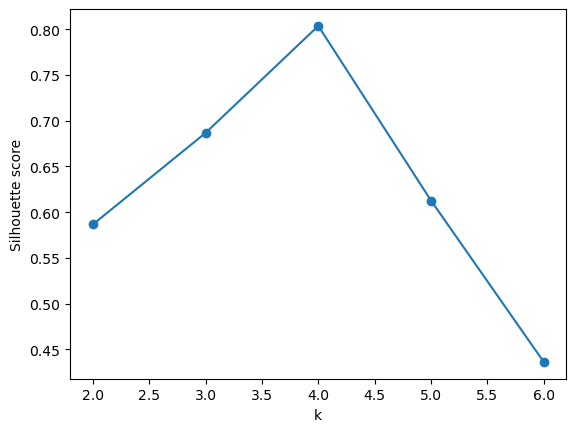

In [13]:
scores.plot(x="k", y="silhouette", marker="o", legend=False)
plt.ylabel("Silhouette score")
plt.show()

### 6. 군집별 대여·반납 패턴은 어떻게 다른가?

`K`를 바꾸어 보고 각 군집의 대표적인 시간대별 패턴을 비교하세요. 네 그래프는 **평일 대여 / 주말 대여 / 평일 반납 / 주말 반납**입니다.

이 그래프의 세로축은 날짜 수를 보정한 **시간대별 비중(%)**입니다. 같은 군집에 속한 대여소들의 비중을 평균해 그립니다.

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\gslee\AppData\Local\Temp\ipykernel_26952\3127368491.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["cluster"] = model.fit_predict(X)


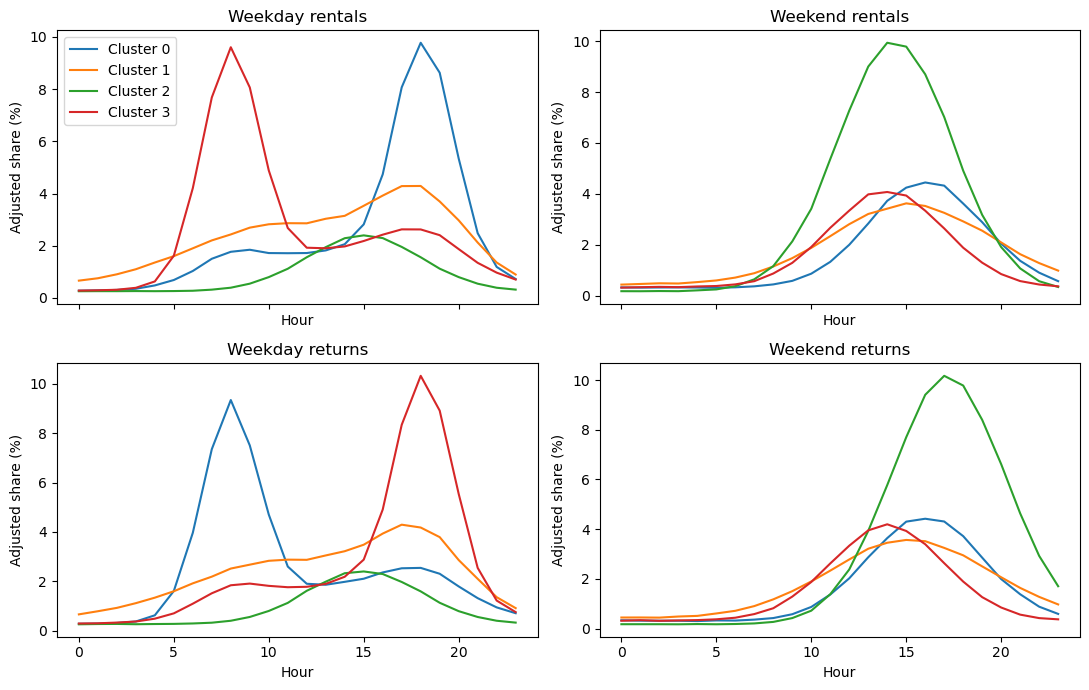

In [14]:
K = 4  # TODO: 실루엣 점수와 그래프를 보고 선택
model = KMeans(n_clusters=K, n_init=10, random_state=42)
bike["cluster"] = model.fit_predict(X)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
parts = [rent_cols[:24], rent_cols[24:], return_cols[:24], return_cols[24:]]
titles = ["Weekday rentals", "Weekend rentals", "Weekday returns", "Weekend returns"]
for ax, cols, title in zip(axes.flat, parts, titles):
    for group, rows in X.groupby(bike["cluster"]):
        ax.plot(range(24), rows[cols].mean().to_numpy() * 100, label=f"Cluster {group}")
    ax.set(title=title, xlabel="Hour", ylabel="Adjusted share (%)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**✍️ 기록 ②**

- 선택한 `K`의 근거는 무엇인가요?
- 어떤 군집은 출근 시간에 **대여**가, 다른 군집은 **반납**이 많은가요?
- 이 군집들은 **서로 다른 대여소 사이의 패턴 유사성**을 바탕으로 만들어졌습니다. 한 대여소에서 평일과 주말이 얼마나 다른지는 아직 직접 측정하지 않았습니다.

## 3주차 · 한 대여소의 평일과 주말은 얼마나 비슷할까?

### 7. 평일·주말 패턴의 차이를 따로 계산하기

지금까지는 **대여소끼리** 비교했습니다. 이번에는 **한 대여소 안에서** 평일과 주말을 비교합니다.

평일의 24시간 대여 비중과 주말의 24시간 대여 비중을 비교하면, 하루 중 이용 시간이 얼마나 달라지는지 알 수 있습니다. 반납도 같은 방식으로 비교합니다.

**패턴 차이(`day_gap`)**는 대여와 반납의 차이를 평균한 값이며 **0~1 사이**입니다.

- **0에 가까울수록:** 평일과 주말의 시간대별 이용 *모양*이 비슷함
- **클수록:** 평일과 주말의 시간대별 이용 *모양*이 다름

여기서는 평일과 주말 각각의 24시간 비중을 따로 합계 1로 만들기 때문에 **하루 이용량의 크기 차이는 반영하지 않습니다.**

In [15]:
def day_pattern(day):
    blocks = []
    for kind in ("r", "b"):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        counts = bike[cols]
        blocks.append(counts.div(counts.sum(axis=1), axis=0))
    return pd.concat(blocks, axis=1)

weekday = day_pattern("wd")
weekend = day_pattern("we")
bike["day_gap"] = abs(weekday.to_numpy() - weekend.to_numpy()).sum(axis=1) / 4

pd.concat([bike.nsmallest(3, "day_gap"), bike.nlargest(3, "day_gap")])[["station_name", "day_gap"]]

C:\Users\gslee\AppData\Local\Temp\ipykernel_26952\3607752828.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["day_gap"] = abs(weekday.to_numpy() - weekend.to_numpy()).sum(axis=1) / 4


,station_name,day_gap
235,모의 대여소 236,0.108861
135,모의 대여소 136,0.114975
131,모의 대여소 132,0.115555
44,모의 대여소 045,0.442494
220,모의 대여소 221,0.436232
24,모의 대여소 025,0.430046


### 8. 패턴이 비슷한 대여소와 다른 대여소를 직접 비교하기

다음은 **하나의 대여소**에서 평일과 주말의 시간대별 비중을 겹쳐 그립니다. 처음에는 `idxmax()`로 **차이가 가장 큰 대여소**를 봅니다. `idxmin()`으로 바꿔 **차이가 가장 작은 대여소**와 비교하세요.

이 그래프는 *각 요일 구분 안에서의 24시간 비중*이므로 평일·주말 총 이용량의 크기를 직접 보여주지는 않습니다.

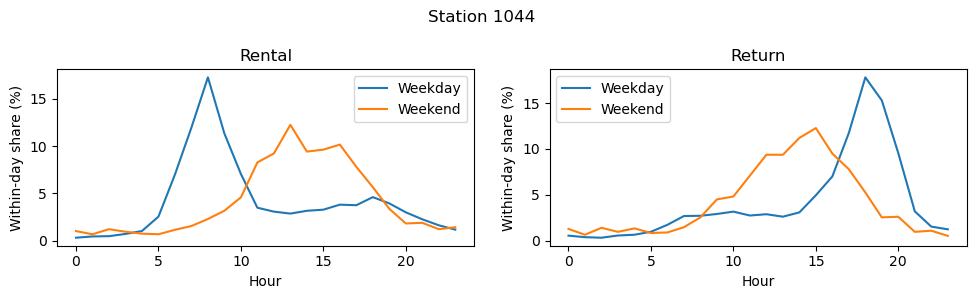

In [16]:
ROW = bike["day_gap"].idxmax()  # TODO: idxmin()으로 바꿔 비교
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, kind, title in zip(axes, ("r", "b"), ("Rental", "Return")):
    for day, label in (("wd", "Weekday"), ("we", "Weekend")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        values = bike.loc[ROW, cols].to_numpy(dtype=float)
        ax.plot(range(24), values / values.sum() * 100, label=label)
    ax.set(title=title, xlabel="Hour", ylabel="Within-day share (%)")
    ax.legend()
plt.suptitle(f"Station {bike.loc[ROW, 'station_id']}")
plt.tight_layout()
plt.show()

### 9. 군집과 평일·주말 차이를 함께 해석하기

**군집 번호**는 다른 대여소들과의 종합적인 유사성을 나타내고, **`day_gap`**은 개별 대여소의 평일·주말 시간 패턴 차이를 나타냅니다. 두 값은 서로 다른 질문에 답합니다.

또한 주말 이용량 자체가 적은지 알아보려면 **평일 하루 평균과 주말 하루 평균 대여건수**도 비교해야 합니다. 아래 `weekend_level`은 둘 중 주말의 비중으로, **0.5면 하루 평균 대여량이 같고 0.5보다 크면 주말이 더 많다**는 뜻입니다.

In [17]:
weekday_avg = bike[rent_cols[:24]].sum(axis=1) / 261
weekend_avg = bike[rent_cols[24:]].sum(axis=1) / 104
bike["weekend_level"] = weekend_avg / (weekday_avg + weekend_avg)

bike.groupby("cluster").agg(
    stations=("station_id", "size"),
    rentals=("annual_rentals", "median"),
    returns=("annual_returns", "median"),
    day_gap=("day_gap", "mean"),
    weekend_level=("weekend_level", "mean")
).round(3)

C:\Users\gslee\AppData\Local\Temp\ipykernel_26952\1387557790.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["weekend_level"] = weekend_avg / (weekday_avg + weekend_avg)


,stations,rentals,returns,day_gap,weekend_level
cluster,,,,,
0,65,42576.0,41160.0,0.379,0.387
1,65,43955.0,41475.0,0.131,0.426
2,65,33465.0,31472.0,0.214,0.778
3,65,31019.0,30537.0,0.417,0.364


**✍️ 기록 ③**

- 어떤 군집에서 평일·주말 패턴의 차이가 큰가요? **모든 대여소가 그런지**도 살펴보세요.
- 패턴 차이가 작더라도 `weekend_level`이 작을 수 있습니다. 이 둘은 무엇이 다른가요?
- 비슷한 평일·주말 패턴을 가진 대여소들이 **반드시 같은 K-means 군집**에 들어가나요?

### 10. 운영 관점에서 대여·반납의 차이 살펴보기

관심 있는 군집의 **대여소 한 곳당 하루 평균 대여·반납건수**를 보세요. 어떤 시간대에 대여가 반납보다 많다면 자전거가 빠져나가는 경향이 있다는 단서가 될 수 있습니다. 다만 실제 재배치가 필요한지는 **재고·거치대 용량·대여소 위치** 등의 자료가 더 필요합니다.

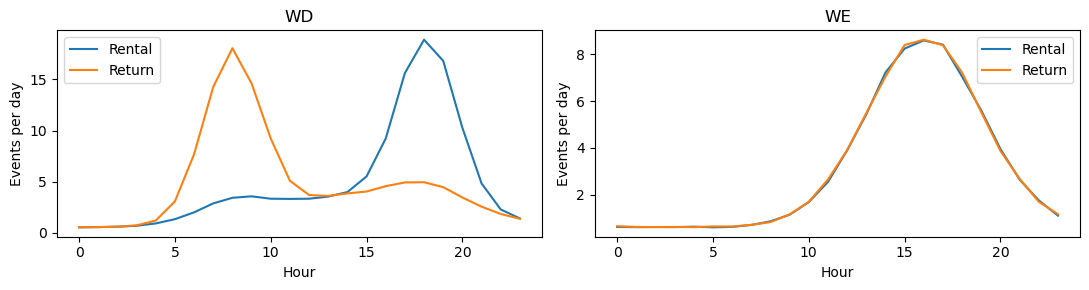

In [18]:
GROUP = 0  # TODO: 관심 있는 군집 번호
selected = bike[bike["cluster"] == GROUP]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ("wd", "we"), (261, 104)):
    for kind, label in (("r", "Rental"), ("b", "Return")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), selected[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 11. 계절적 특징도 살펴보기

`m01`~`m12`는 **월별 대여 총건수**입니다. 이를 각 대여소의 연간 대여건수로 나누면 월별 비중을 비교할 수 있습니다. 군집별로 어느 계절에 이용이 집중되는지 살펴보세요.

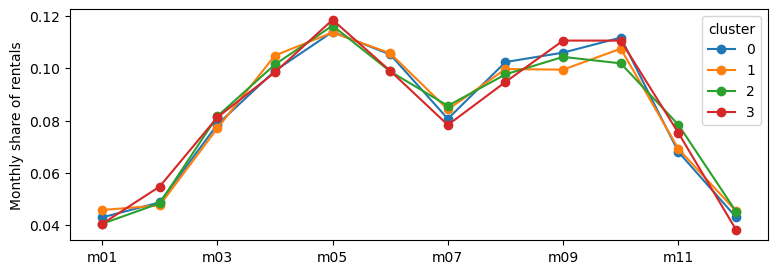

In [19]:
months = [f"m{m:02}" for m in range(1, 13)]
monthly_share = bike[months].div(bike["annual_rentals"], axis=0)
monthly_share.groupby(bike["cluster"]).mean().T.plot(marker="o", figsize=(9, 3))
plt.ylabel("Monthly share of rentals")
plt.show()

### 12. 최종 분석: 유형 이름과 운영 방안 제안

아래 표를 채우며 **그래프에서 관찰한 사실**과 **실제 이용 목적에 관한 가설**을 구분하세요.

| 군집 | 평일 대여·반납 특징 | 주말 대여·반납 특징 | `day_gap` 특징 | 임시 이름·운영 제안 |
|---|---|---|---|---|
| 0 | | | | |
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

군집 수 `K`를 변경했다면 행을 알맞게 바꾸세요.

**✍️ 최종 판단**

1. **대여소 간 유사성**과 **한 대여소 내 평일·주말 유사성**을 구분해 설명하세요.
2. 발견한 군집에 이름을 붙이고, **근거가 되는 그래프**를 제시하세요.
3. 운영 개선 방안 하나를 제안하고, **추가로 필요한 정보**를 적으세요.
4. **AI 활용:** AI가 제안한 군집 이름·운영 방안을 검토하고, 과장된 해석을 하나 수정하세요.

**주의:** K-means는 이용 목적이나 재배치 필요성을 직접 증명하지 않습니다.

## 선택 활동 A · 평일에 비슷한 대여소는 주말에도 비슷할까?

앞에서는 **96개 특성을 합쳐 한 번에 군집화**했습니다. 여기서는 평일과 주말의 **24시간 대여·반납 패턴을 따로 군집화**합니다.

아래 교차표에서 **같은 행**에 속한 대여소들은 평일 패턴이 비슷하고, **같은 열**에 속한 대여소들은 주말 패턴이 비슷합니다. **같은 칸**은 두 기준에서 모두 비슷한 대여소 집합입니다.

단, 평일 군집 `0`과 주말 군집 `0`은 **같은 유형이라는 뜻이 아닙니다.** 각 요일 구분에서 따로 학습했기 때문에 번호에는 공통된 의미가 없습니다.

In [20]:
K_DAY = 3  # TODO: 평일·주말 각각의 군집 수
bike["weekday_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekday)
bike["weekend_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekend)
pd.crosstab(bike["weekday_group"], bike["weekend_group"])

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\gslee\AppData\Local\Temp\ipykernel_26952\3846122299.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["weekday_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekday)
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREAD

weekend_group,0,1,2
weekday_group,,,
0,65,0,0
1,65,65,0
2,0,0,65


**✍️ 추가 질문:** 평일에는 같은 군집이지만 주말에는 다른 군집에 속한 대여소들을 찾을 수 있나요? 한 대여소의 `day_gap`이 낮다는 사실과, 서로 다른 두 대여소가 **같은 군집**에 속한다는 사실은 어떻게 다른가요?

## 선택 활동 B · 2024년과 비교하기

2024년 데이터를 같은 형식으로 준비했다면, **2025년 K-means 모델을 그대로 사용해** 2024년 대여소들의 유형을 분류할 수 있습니다. 이때 **2024년은 평일 262일, 주말 104일**이므로 날짜 수를 다시 보정해야 합니다.

아래 코드는 **2024년 CSV가 있을 때에만** 실행합니다. 2024년과 2025년에 모두 포함된 대여소만 비교합니다.

```python
old = pd.read_csv("p5_station_profiles_2024.csv", dtype={"station_id": str}).set_index("station_id")
now = bike.set_index("station_id")
common = old.index.intersection(now.index)

old_daily = old.loc[common, rent_cols + return_cols].astype(float).copy()
old_daily[rent_cols[:24] + return_cols[:24]] /= 262
old_daily[rent_cols[24:] + return_cols[24:]] /= 104
old_r = old_daily[rent_cols].div(old_daily[rent_cols].sum(axis=1), axis=0)
old_b = old_daily[return_cols].div(old_daily[return_cols].sum(axis=1), axis=0)
old_group = model.predict(pd.concat([old_r, old_b], axis=1))

pd.crosstab(old_group, now.loc[common, "cluster"].to_numpy(), normalize="index").round(2)
```

2025년 군집 기준을 2024년에 적용한 결과이므로, **두 해에서 독립적으로 만든 군집의 일치율**을 뜻하지 않습니다. 대여소 신설·폐쇄, 운영 기간, 기록 방식의 차이에도 주의하세요.

---

### 최종 제출

**실행한 노트북 + 분석 보고서 1~2쪽**

**문제 정의 → 데이터 이해 → 군집 수 선택 → 군집별 평일·주말 패턴 → 대여소 내 패턴 차이 → 운영 제안과 한계** 순서로 작성하세요.

- 코드를 길게 작성하는 것보다 **실험과 판단 근거**를 중요하게 평가합니다.
- 모의 데이터는 실습용이며 실제 서울 따릉이 분석 결과가 아닙니다.
- 원자료: [서울 열린데이터광장 — 공공자전거 대여이력](https://data.seoul.go.kr/dataList/OA-15182/F/1/datasetView.do)
- 실제 분석은 교수자 전처리 코드로 만든 `p5_station_profiles_2025.csv`를 사용합니다.